In [1]:
import sys
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import seaborn as sns

ROOT = Path.cwd()

FITS_DIR = ROOT / "fits_files"
FIGS_DIR = ROOT / "figures"
FIGS_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "py_modules"))

import results_comp
import fit_fraction_latex_tools as ffa

ffa = importlib.reload(ffa)

sns.set_context("talk")


Configuration

In [2]:
ALL_FIT_LIMITS = (
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
)

In [3]:
DATASET_CONFIGS = [
    {
        "group": "MUSE",
        "dataset_prefix": "MUSE-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),
        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },

    {
        "group": "SAMFP",
        "dataset_prefix": "SAMFP-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        # Internal key H, but filename uses Ha
        "file_line_ids": {
            "H": "Ha",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },
]

Preview the expected files

In [4]:
samples = ffa.build_fraction_sample_grid(
    DATASET_CONFIGS,
    ALL_FIT_LIMITS,
)

sample_table = pd.DataFrame(samples)[
    ["group", "bin", "line", "fit_limit", "file_name"]
]

display(sample_table)

,group,bin,line,fit_limit,file_name
0,MUSE,0,H,0.2,MUSE-30Dor-H-bin0_02
1,MUSE,0,H,0.3,MUSE-30Dor-H-bin0_03
2,MUSE,0,H,0.4,MUSE-30Dor-H-bin0_04
3,MUSE,0,H,0.5,MUSE-30Dor-H-bin0_05
4,MUSE,0,H,0.6,MUSE-30Dor-H-bin0_06
5,MUSE,0,H,0.7,MUSE-30Dor-H-bin0_07
6,MUSE,0,H,0.8,MUSE-30Dor-H-bin0_08
7,MUSE,0,H,0.9,MUSE-30Dor-H-bin0_09
8,MUSE,0,H,1.0,MUSE-30Dor-H-bin0_10
9,SAMFP,0,H,0.2,SAMFP-30Dor-Ha-bin0_02


Load the complete \(L_{\rm frac}\)

In [5]:
all_fraction_results, failures = (
    ffa.load_multi_line_bin_fraction_results(
        results_comp,
        FITS_DIR,
        dataset_configs=DATASET_CONFIGS,
        fit_limits=ALL_FIT_LIMITS,
        read_header=True,
        on_error="warn",
        return_failures=True,
    )
)

print(f"Loaded: {len(all_fraction_results)}")
print(f"Unavailable: {len(failures)}")

if failures:
    display(
        pd.DataFrame(failures)[
            ["file_name", "error"]
        ]
    )

Loaded: 18
Unavailable: 0


Convert the complete sample to a tidy table

In [6]:
fraction_table = ffa.results_to_dataframe(
    all_fraction_results
)

display(fraction_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,0.2,None,None,sig2,266.788715,24.830140,460.949573,241.958575,727.738289,None
1,MUSE,0,H,0.2,None,None,r0,2.560088,0.347458,12.407244,2.212630,14.967333,None
2,MUSE,0,H,0.2,None,None,m,0.964042,0.268651,0.056073,0.695391,1.020116,None
3,MUSE,0,H,0.2,None,None,noise,5.247113,0.400805,0.488660,4.846308,5.735772,None
4,MUSE,0,H,0.2,None,None,s0,0.105187,0.015375,0.080311,0.089811,0.185497,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,SAMFP,0,H,1.0,None,None,sig2,630.357706,226.034290,224.887743,404.323416,855.245448,None
86,SAMFP,0,H,1.0,None,None,r0,25.279368,15.088768,20.557432,10.190600,45.836800,None
87,SAMFP,0,H,1.0,None,None,m,0.659333,0.058224,0.086868,0.601109,0.746201,None
88,SAMFP,0,H,1.0,None,None,noise,4.766073,0.641635,0.650147,4.124438,5.416220,None


Section 3 — inspect the complete \(L_{\rm frac}\) sample

In [7]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

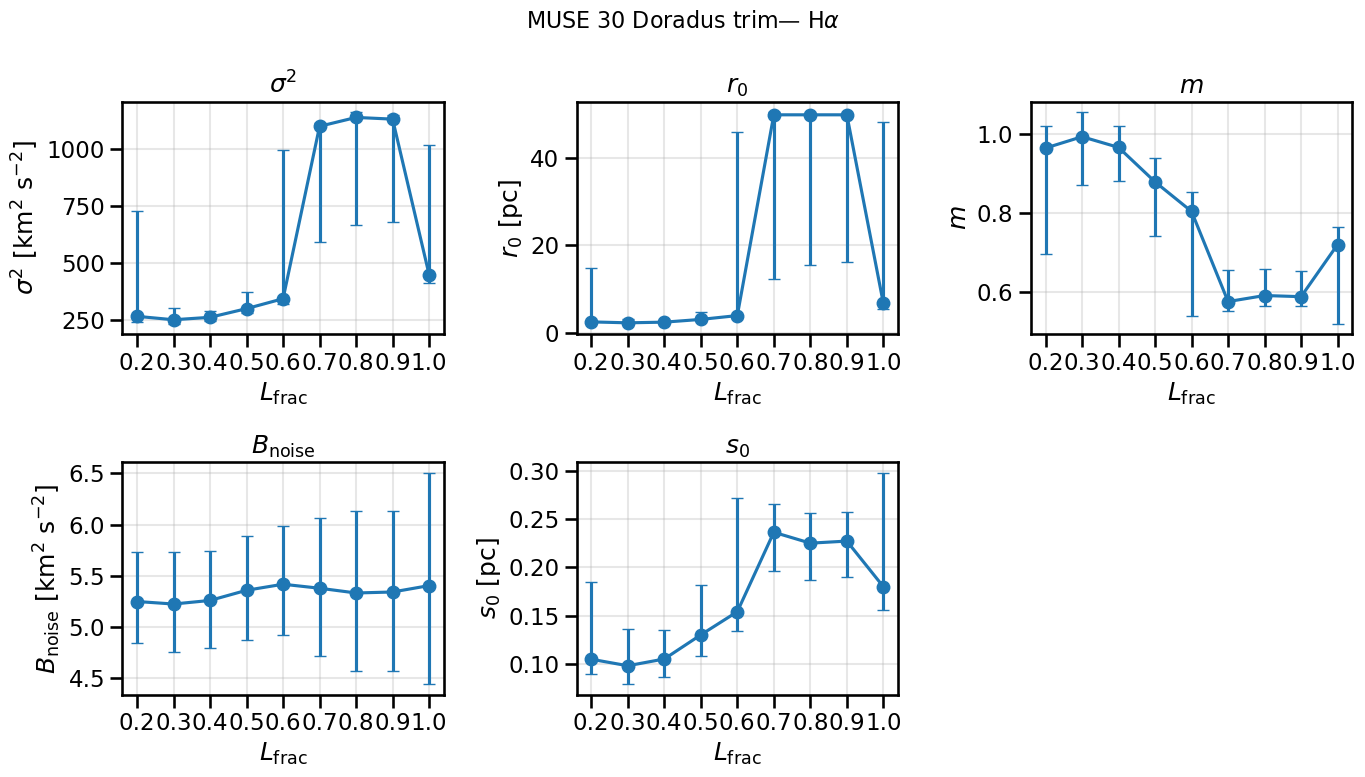

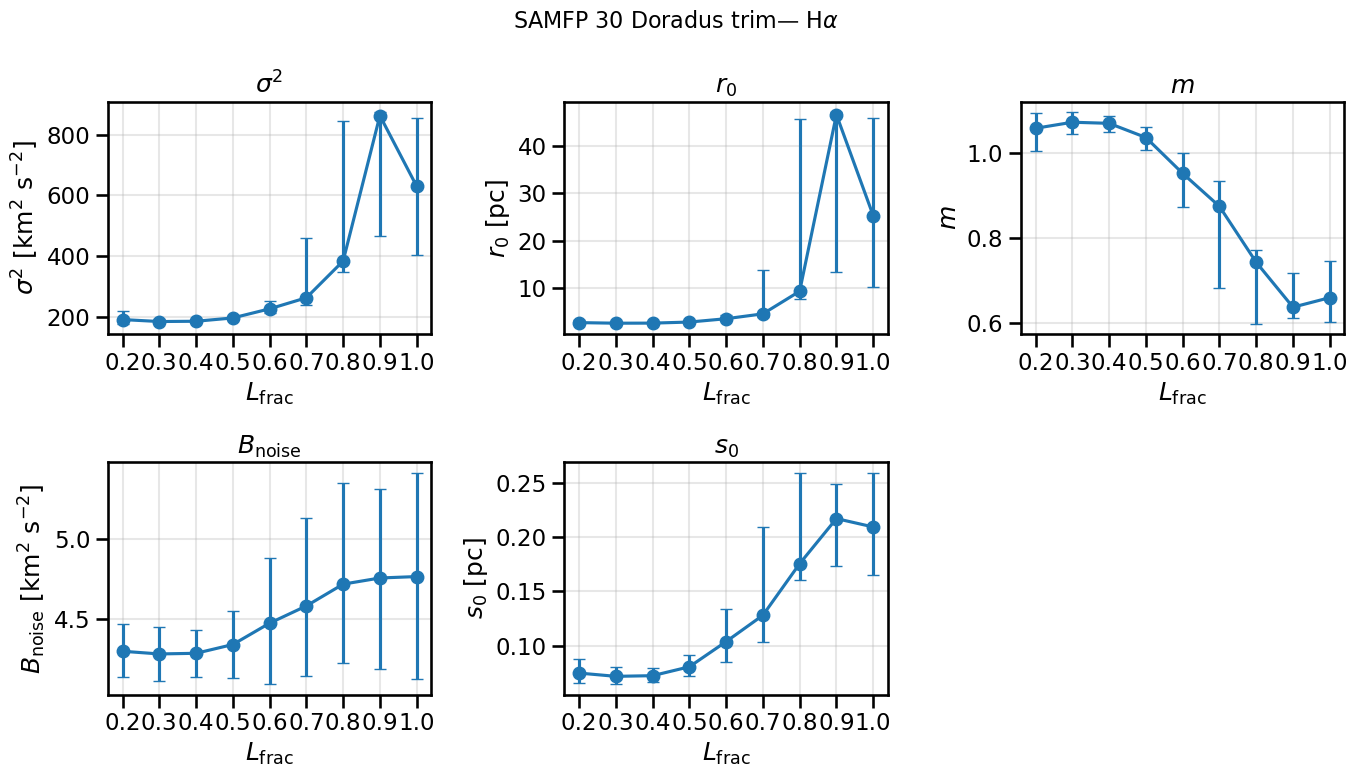

In [24]:
GROUPS_TO_PLOT = tuple(
    dict.fromkeys(fraction_table["group"])
)

for group in GROUPS_TO_PLOT:

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    # Fit limits actually available for this instrument
    group_fit_limits = tuple(
        sorted(
            fraction_table.loc[
                fraction_table["group"] == group,
                "fit_limit",
            ].unique()
        )
    )

    for ax, param in zip(axes, PARAMETERS):

        df_param = (
            fraction_table[
                (fraction_table["parameter"] == param)
                &
                (fraction_table["group"] == group)
            ]
            .sort_values("fit_limit")
        )

        x = df_param["fit_limit"].to_numpy()
        y = df_param["value"].to_numpy(dtype=float)

        err_lower = df_param["err_lower"].to_numpy(dtype=float)
        err_upper = df_param["err_upper"].to_numpy(dtype=float)

        # --------------------------------------------------
        # Lower uncertainty
        #
        # If the stored lower uncertainty is negative,
        # interpret it as reaching the physical boundary
        # at zero. Therefore the lower error magnitude
        # becomes equal to the central value.
        # --------------------------------------------------
        bad_lower = err_lower < 0

        if np.any(bad_lower):
            print(
                f"{group} — {param}: negative lower uncertainty "
                f"at Lfrac = "
                f"{df_param.loc[bad_lower, 'fit_limit'].tolist()} "
                "-> lower limit set to zero"
            )

        err_lower_plot = np.where(
            bad_lower,
            y,
            np.abs(err_lower),
        )

        # Upper errors must be positive magnitudes
        err_upper_plot = np.abs(err_upper)

        yerr = np.vstack([
            err_lower_plot,
            err_upper_plot,
        ])

        # --------------------------------------------------
        # Plot
        # --------------------------------------------------
        ax.errorbar(
            x,
            y,
            yerr=yerr,
            marker="o",
            linestyle="-",
            capsize=4,
            label="Individual fits",
        )

        ax.set_title(
            PARAM_TITLES[param]
        )

        ax.set_xlabel(
            r"$L_{\rm frac}$"
        )

        ax.set_ylabel(
            PARAM_LABELS[param]
        )

        ax.set_xticks(
            group_fit_limits
        )

        ax.grid(
            alpha=0.3
        )

    # --------------------------------------------------
    # Empty panel
    # --------------------------------------------------
    axes[-1].axis("off")

    # --------------------------------------------------
    # Figure title
    # --------------------------------------------------
    fig.suptitle(
        rf"{group} 30 Doradus trim— H$\alpha$",
        fontsize=16,
    )

    fig.tight_layout()

    plt.show()

Visually indicate the fractions selected for the final result

In [9]:
SELECTED_FIT_LIMITS = (0.2, 0.3, 0.4)

In [10]:
FIT_LIMITS_BY_GROUP = {
    "MUSE": (
        0.3,
        0.4,
        0.5,
    ),

    "SAMFP": (
        0.3,
        0.4,
        0.5,
    ),
}

In [11]:
# Selected fit limits for this instrument
selected_fit_limits = FIT_LIMITS_BY_GROUP[group]

selected_min = min(selected_fit_limits)
selected_max = max(selected_fit_limits)

# Highlight adopted Lfrac interval
ax.axvspan(
    selected_min,
    selected_max,
    alpha=0.10,
)

# Identify the individual fits used in the adopted result
selected_mask = df_param["fit_limit"].isin(
    selected_fit_limits
)

ax.scatter(
    df_param.loc[selected_mask, "fit_limit"],
    df_param.loc[selected_mask, "value"],
    s=90,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5,
)

Downstream selection and averaging

In [12]:
selected_results_pc = (
    ffa.select_or_average_fit_results(
        all_fraction_results,
        fit_limits_by_group=FIT_LIMITS_BY_GROUP,
        group_keys=("group", "bin", "line"),
    )
)

selected_table_pc = ffa.results_to_dataframe(
    selected_results_pc
)

display(selected_table_pc)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,sig2,271.652340,38.033540,102.604528,233.618800,374.256869,3
1,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,r0,2.657807,0.554782,2.104948,2.103026,4.762756,3
2,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,m,0.945571,0.204773,0.109666,0.740798,1.055237,3
3,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,noise,5.279045,0.530282,0.604269,4.748763,5.883314,3
4,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,s0,0.111429,0.032127,0.070362,0.079301,0.181790,3
5,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,sig2,187.761235,10.441282,14.533879,177.319954,202.295114,3
6,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,r0,2.639323,0.209298,0.313453,2.430025,2.952776,3
7,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,m,1.060890,0.053240,0.036786,1.007650,1.097676,3
8,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,noise,4.303543,0.188070,0.249528,4.115472,4.553070,3
9,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,s0,0.075063,0.010442,0.016184,0.064622,0.091247,3


In [13]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

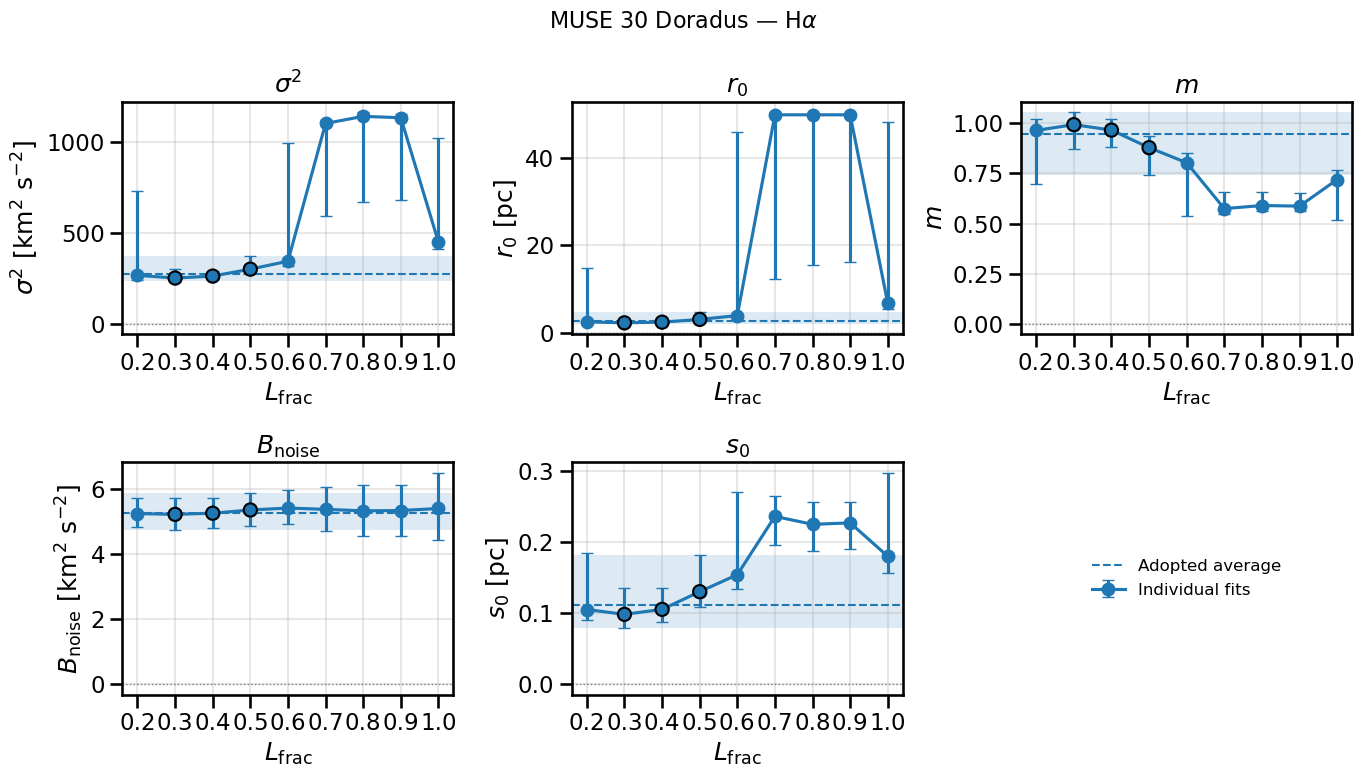

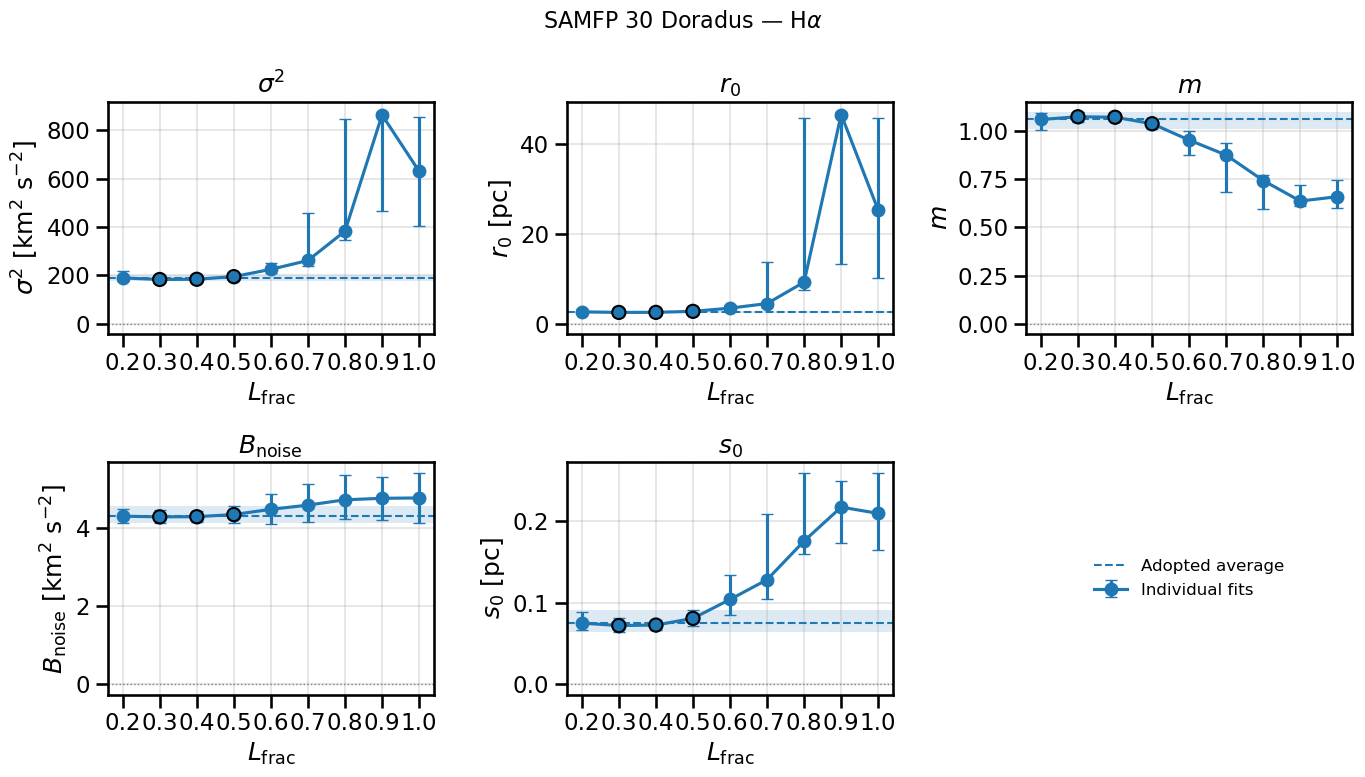

In [14]:
GROUPS_TO_PLOT = tuple(
    dict.fromkeys(fraction_table["group"])
)

for group in GROUPS_TO_PLOT:

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    # Selected Lfrac values for this instrument
    selected_fit_limits = FIT_LIMITS_BY_GROUP[group]

    # Fit limits available for this instrument
    group_fit_limits = tuple(
        sorted(
            fraction_table.loc[
                fraction_table["group"] == group,
                "fit_limit",
            ].unique()
        )
    )

    for ax, param in zip(axes, PARAMETERS):

        # --------------------------------------------------
        # Complete Lfrac sample for this instrument
        # --------------------------------------------------
        df_raw = (
            fraction_table[
                (fraction_table["parameter"] == param)
                &
                (fraction_table["group"] == group)
            ]
            .sort_values("fit_limit")
        )

        x = df_raw["fit_limit"].to_numpy()
        y = df_raw["value"].to_numpy(dtype=float)

        err_lower = df_raw["err_lower"].to_numpy(dtype=float)
        err_upper = df_raw["err_upper"].to_numpy(dtype=float)

        # --------------------------------------------------
        # Error-bar treatment
        #
        # Negative lower uncertainties are interpreted as
        # extending to the physical boundary at zero.
        # --------------------------------------------------
        bad_lower = err_lower < 0

        err_lower_plot = np.where(
            bad_lower,
            y,
            np.abs(err_lower),
        )

        err_upper_plot = np.abs(
            err_upper
        )

        yerr = np.vstack([
            err_lower_plot,
            err_upper_plot,
        ])

        ax.errorbar(
            x,
            y,
            yerr=yerr,
            marker="o",
            linestyle="-",
            capsize=4,
            label="Individual fits",
        )

        # --------------------------------------------------
        # Selected / averaged result for this instrument
        # --------------------------------------------------
        df_avg = selected_table_pc[
            (selected_table_pc["parameter"] == param)
            &
            (selected_table_pc["group"] == group)
        ]

        if len(df_avg) == 1:

            avg = float(
                df_avg["value"].iloc[0]
            )

            avg_lower = float(
                df_avg["err_lower"].iloc[0]
            )

            avg_upper = float(
                df_avg["err_upper"].iloc[0]
            )

            # Same convention for a negative
            # lower uncertainty
            if avg_lower < 0:
                lower_limit = 0.0
            else:
                lower_limit = avg - abs(avg_lower)

            upper_limit = (
                avg + abs(avg_upper)
            )

            # Mean adopted value
            ax.axhline(
                avg,
                linestyle="--",
                linewidth=1.5,
                label="Adopted average",
            )

            # Full uncertainty envelope
            ax.axhspan(
                lower_limit,
                upper_limit,
                alpha=0.15,
            )

        # --------------------------------------------------
        # Mark selected Lfrac values
        # --------------------------------------------------
        selected_mask = (
            df_raw["fit_limit"]
            .isin(selected_fit_limits)
        )

        ax.scatter(
            df_raw.loc[
                selected_mask,
                "fit_limit",
            ],
            df_raw.loc[
                selected_mask,
                "value",
            ],
            s=90,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5,
            zorder=5,
        )

        # --------------------------------------------------
        # Reference line
        # --------------------------------------------------
        ax.axhline(
            0.0,
            color="0.5",
            linestyle=":",
            linewidth=1.0,
        )

        # --------------------------------------------------
        # Axes
        # --------------------------------------------------
        ax.set_title(
            PARAM_TITLES[param]
        )

        ax.set_xlabel(
            r"$L_{\rm frac}$"
        )

        ax.set_ylabel(
            PARAM_LABELS[param]
        )

        ax.set_xticks(
            group_fit_limits
        )

        ax.grid(
            alpha=0.3
        )

    # --------------------------------------------------
    # Legend in empty panel
    # --------------------------------------------------
    axes[-1].axis("off")

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    axes[-1].legend(
        handles,
        labels,
        loc="center",
        frameon=False,
        fontsize=12,
    )

    # --------------------------------------------------
    # Figure title
    # --------------------------------------------------
    fig.suptitle(
        rf"{group} 30 Doradus — H$\alpha$",
        fontsize=16,
    )

    fig.tight_layout()

    # --------------------------------------------------
    # Save
    # --------------------------------------------------
    fig.savefig(
        FIGS_DIR
        / f"{group}_30Dor_H_Lfrac_diagnostics.jpg",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

In [15]:
adopted_table = (
    selected_table_pc[
        ["parameter", "value", "err_lower", "err_upper"]
    ]
    .copy()
)

display(adopted_table)

,parameter,value,err_lower,err_upper
0,sig2,271.652340,38.033540,102.604528
1,r0,2.657807,0.554782,2.104948
2,m,0.945571,0.204773,0.109666
3,noise,5.279045,0.530282,0.604269
4,s0,0.111429,0.032127,0.070362
5,sig2,187.761235,10.441282,14.533879
6,r0,2.639323,0.209298,0.313453
7,m,1.060890,0.053240,0.036786
8,noise,4.303543,0.188070,0.249528
9,s0,0.075063,0.010442,0.016184


In [16]:
selected_results = ffa.convert_s0_pc_to_arcsec(
    selected_results_pc,
    fwhm_factor=2.355,
    copy=True,
)

selected_table = ffa.results_to_dataframe(
    selected_results
)

display(selected_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,sig2,271.652340,38.033540,102.604528,233.618800,374.256869,3
1,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,r0,2.657807,0.554782,2.104948,2.103026,4.762756,3
2,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,m,0.945571,0.204773,0.109666,0.740798,1.055237,3
3,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,noise,5.279045,0.530282,0.604269,4.748763,5.883314,3
4,MUSE,0,H,None,"(0.3, 0.4, 0.5)",average,s0,1.082536,0.312120,0.683569,0.770416,1.766105,3
5,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,sig2,187.761235,10.441282,14.533879,177.319954,202.295114,3
6,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,r0,2.639323,0.209298,0.313453,2.430025,2.952776,3
7,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,m,1.060890,0.053240,0.036786,1.007650,1.097676,3
8,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,noise,4.303543,0.188070,0.249528,4.115472,4.553070,3
9,SAMFP,0,H,None,"(0.3, 0.4, 0.5)",average,s0,0.729246,0.101443,0.157227,0.627804,0.886474,3


In [17]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS_FINAL = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

Groups: ('MUSE', 'SAMFP')


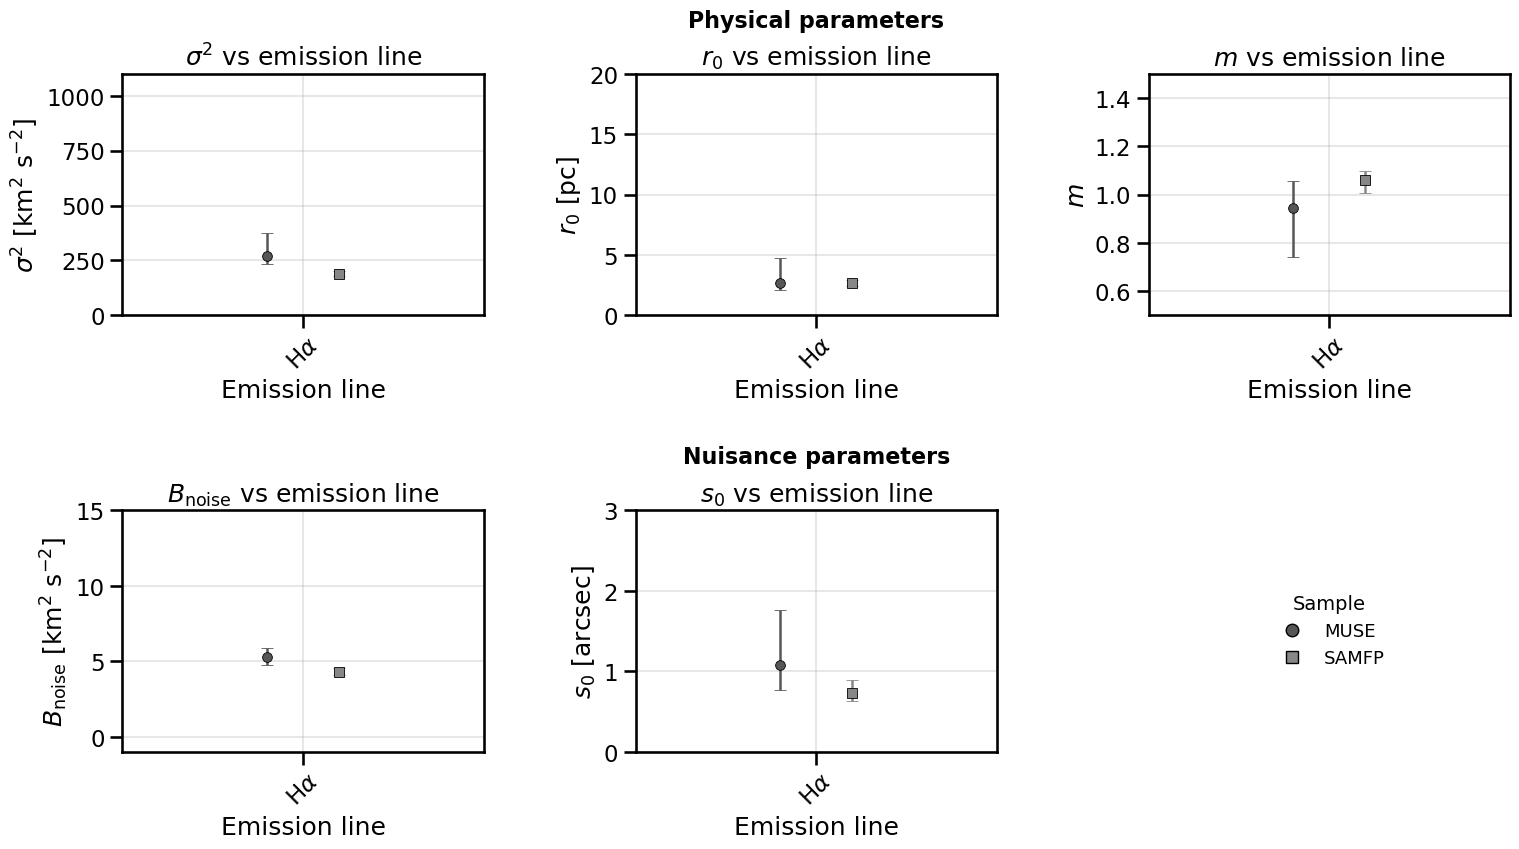

In [18]:
sample_selected = selected_results

# --------------------------------------------------
# Labels
# --------------------------------------------------

LINE_LABELS = {
    "H": r"H$\alpha$",
}

PARAM_LABELS_ARCSEC = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}


# --------------------------------------------------
# Instrument order
#
# Automatically obtained from the selected sample.
# Current result:
# ("MUSE", "SAMFP")
# --------------------------------------------------

GROUP_ORDER = tuple(
    dict.fromkeys(
        entry["group"]
        for entry in sample_selected
    )
)

print("Groups:", GROUP_ORDER)


# --------------------------------------------------
# Plot adopted results
# --------------------------------------------------

fig_samples, axes_samples = ffa.plot_param_grid_lines_as_x(
    sample_selected,

    line_order=("H",),

    group_order=GROUP_ORDER,
    group_key="group",

    line_labels=LINE_LABELS,
    param_labels=PARAM_LABELS_ARCSEC,

    param_ylims={
        "sig2": (0, 1100),
        "r0": (0, 20),
        "m": (0.5, 1.5),
        "noise": (-1, 15),
        "s0": (0, 3),
    },

    row_titles=(
        "Physical parameters",
        "Nuisance parameters",
    ),

    row_title_fontsize=16,
    figsize=(15, 9),

    jitter=0.10,

    save=True,
    savepath=FIGS_DIR / "fit_fraction_average_by_sample_trim.pdf",
)


# --------------------------------------------------
# Panel formatting
# --------------------------------------------------

for ax in axes_samples[:5]:
    ax.set_box_aspect(None)
    ax.set_aspect("auto")


fig_samples.subplots_adjust(
    left=0.065,
    right=0.99,
    wspace=0.42,
)

plt.show()

In [19]:
adopted_summary = (
    selected_table[
        [
            "group",
            "line",
            "fit_limits_used",
            "parameter",
            "value",
            "err_lower",
            "err_upper",
        ]
    ]
    .copy()
)

display(adopted_summary)

,group,line,fit_limits_used,parameter,value,err_lower,err_upper
0,MUSE,H,"(0.3, 0.4, 0.5)",sig2,271.652340,38.033540,102.604528
1,MUSE,H,"(0.3, 0.4, 0.5)",r0,2.657807,0.554782,2.104948
2,MUSE,H,"(0.3, 0.4, 0.5)",m,0.945571,0.204773,0.109666
3,MUSE,H,"(0.3, 0.4, 0.5)",noise,5.279045,0.530282,0.604269
4,MUSE,H,"(0.3, 0.4, 0.5)",s0,1.082536,0.312120,0.683569
5,SAMFP,H,"(0.3, 0.4, 0.5)",sig2,187.761235,10.441282,14.533879
6,SAMFP,H,"(0.3, 0.4, 0.5)",r0,2.639323,0.209298,0.313453
7,SAMFP,H,"(0.3, 0.4, 0.5)",m,1.060890,0.053240,0.036786
8,SAMFP,H,"(0.3, 0.4, 0.5)",noise,4.303543,0.188070,0.249528
9,SAMFP,H,"(0.3, 0.4, 0.5)",s0,0.729246,0.101443,0.157227


Build the final adopted-parameter table

In [20]:
FINAL_PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

# Automatically determine the available groups
GROUP_ORDER = tuple(
    dict.fromkeys(selected_table["group"])
)

final_rows = []

for group in GROUP_ORDER:

    df_group = selected_table[
        selected_table["group"] == group
    ]

    if df_group.empty:
        continue

    row = {
        "group": group,
        "line": df_group["line"].iloc[0],
        "fit_limits_used": df_group["fit_limits_used"].iloc[0],
    }

    for param in FINAL_PARAMETERS:

        df_param = df_group[
            df_group["parameter"] == param
        ]

        if df_param.empty:
            continue

        values = df_param.iloc[0]

        row[param] = values["value"]
        row[f"{param}_err_lower"] = values["err_lower"]
        row[f"{param}_err_upper"] = values["err_upper"]

    final_rows.append(row)

final_table = pd.DataFrame(final_rows)

display(final_table)

,group,line,fit_limits_used,sig2,sig2_err_lower,sig2_err_upper,r0,r0_err_lower,r0_err_upper,m,m_err_lower,m_err_upper,noise,noise_err_lower,noise_err_upper,s0,s0_err_lower,s0_err_upper
0,MUSE,H,"(0.3, 0.4, 0.5)",271.652340,38.033540,102.604528,2.657807,0.554782,2.104948,0.945571,0.204773,0.109666,5.279045,0.530282,0.604269,1.082536,0.312120,0.683569
1,SAMFP,H,"(0.3, 0.4, 0.5)",187.761235,10.441282,14.533879,2.639323,0.209298,0.313453,1.060890,0.053240,0.036786,4.303543,0.188070,0.249528,0.729246,0.101443,0.157227


In [21]:
LATEX_LINE = "H"
LATEX_BIN = 0

latex_rows = []

for group in GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=LATEX_BIN,
        line=LATEX_LINE,
    )

    row = ffa.format_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )

    latex_rows.append(row)

print("\n".join(latex_rows))

MUSE & 0 & H$\alpha$ & 0.3,0.4,0.5 & 271.65\PM{102.60}{38.03} & 2.658\PM{2.105}{0.555} & 0.95\PM{0.11}{0.20} & 5.279\PM{0.604}{0.530} & <1.77 & 10.14 & <0.0684 & 0.018 \\
SAMFP & 0 & H$\alpha$ & 0.3,0.4,0.5 & 187.76\PM{14.53}{10.44} & 2.639\PM{0.313}{0.209} & 1.06\PM{0.04}{0.05} & 4.304\PM{0.250}{0.188} & <0.89 & 9.34 & <0.0346 & 0.017 \\


In [22]:
for group in GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=0,
        line="H",
    )

    print(f"\n--- {group} ---")

    ffa.print_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )


--- MUSE ---
MUSE & 0 & H$\alpha$ & 0.3,0.4,0.5 & 271.65\PM{102.60}{38.03} & 2.658\PM{2.105}{0.555} & 0.95\PM{0.11}{0.20} & 5.279\PM{0.604}{0.530} & <1.77 & 10.14 & <0.0684 & 0.018 \\

--- SAMFP ---
SAMFP & 0 & H$\alpha$ & 0.3,0.4,0.5 & 187.76\PM{14.53}{10.44} & 2.639\PM{0.313}{0.209} & 1.06\PM{0.04}{0.05} & 4.304\PM{0.250}{0.188} & <0.89 & 9.34 & <0.0346 & 0.017 \\


Export the adopted sample

In [23]:
OUTPUT_TABLE = ROOT / "fit_fraction_selected_results.csv"

final_table.to_csv(
    OUTPUT_TABLE,
    index=False,
)

print(f"Saved table to {OUTPUT_TABLE}")

Saved table to C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1_trim\fit_fraction_selected_results.csv
